# 1. Perkenalan Dataset

Tahap pertama, eksperimen menggunakan dataset yang berasal dari repositori publik UCI Machine Learning Repository. Dataset dipilih untuk eksperimen klasifikasi dan bukan termasuk Iris, MNIST, Credit Scoring, atau Wine Quality.

**Nama dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset  
**Sumber dataset:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

Dataset memuat 569 sampel dan 30 fitur numerik yang dihitung dari citra digital aspirasi jarum halus (fine needle aspirate/FNA) massa payudara, untuk memprediksi diagnosis `malignant` atau `benign`. Dalam data scikit-learn, label 0 adalah `malignant` dan label 1 adalah `benign`. Eksperimen ini hanya untuk pembelajaran machine learning dan bukan alat diagnosis medis.

Template meminta sumber dataset publik yang jelas. Dataset UCI tersebut dimuat pada notebook dengan fungsi `load_breast_cancer` dari scikit-learn.

# 2. Import Library

Pada tahap ini, impor pustaka Python yang dibutuhkan untuk memuat dan menganalisis data, membuat visualisasi, membagi data, melakukan imputasi dan standardisasi, serta menyimpan hasil preprocessing sebagai CSV.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 3. Memuat Dataset

Pada tahap ini, dataset dimuat dan beberapa baris awal diperiksa untuk memahami strukturnya. Dataset bersumber dari UCI Machine Learning Repository dan tersedia melalui `load_breast_cancer(as_frame=True)` di scikit-learn. Argumen `as_frame=True` menghasilkan DataFrame pandas. Fitur berisi pengukuran numerik inti sel dari citra FNA, sedangkan target menunjukkan diagnosis malignant atau benign.

In [3]:
dataset = load_breast_cancer(as_frame=True)
data = dataset.data.copy()
data["target"] = dataset.target
data["diagnosis"] = data["target"].map(dict(enumerate(dataset.target_names)))

print("Ukuran dataset:", data.shape)
print("\nLima baris pertama:")
display(data.head())
print("\nNama fitur:", list(dataset.feature_names))
print("Kelas target:", list(dataset.target_names))

Ukuran dataset: (569, 32)

Lima baris pertama:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant



Nama fitur: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Kelas target: ['malignant', 'benign']


# 4. Exploratory Data Analysis (EDA)

Pada tahap ini, lakukan Exploratory Data Analysis (EDA) untuk memahami karakteristik dataset dan memperoleh wawasan awal. Analisis mencakup struktur, statistik fitur, nilai kosong, duplikasi, distribusi kelas, dan distribusi fitur.

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothn

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Jumlah nilai kosong per kolom:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
diagnosis                  0
dtype: int64

Jumlah baris duplikat: 0



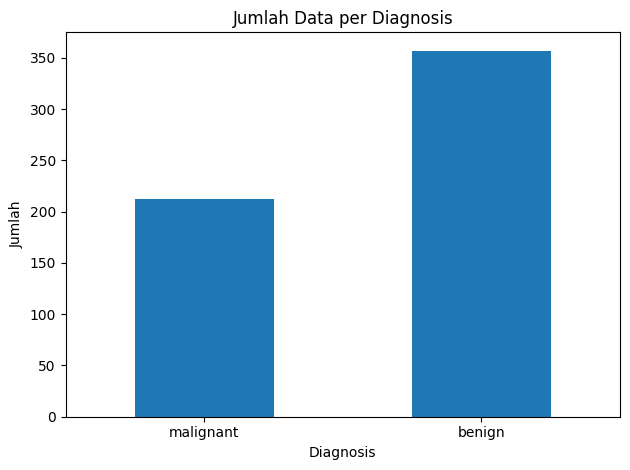

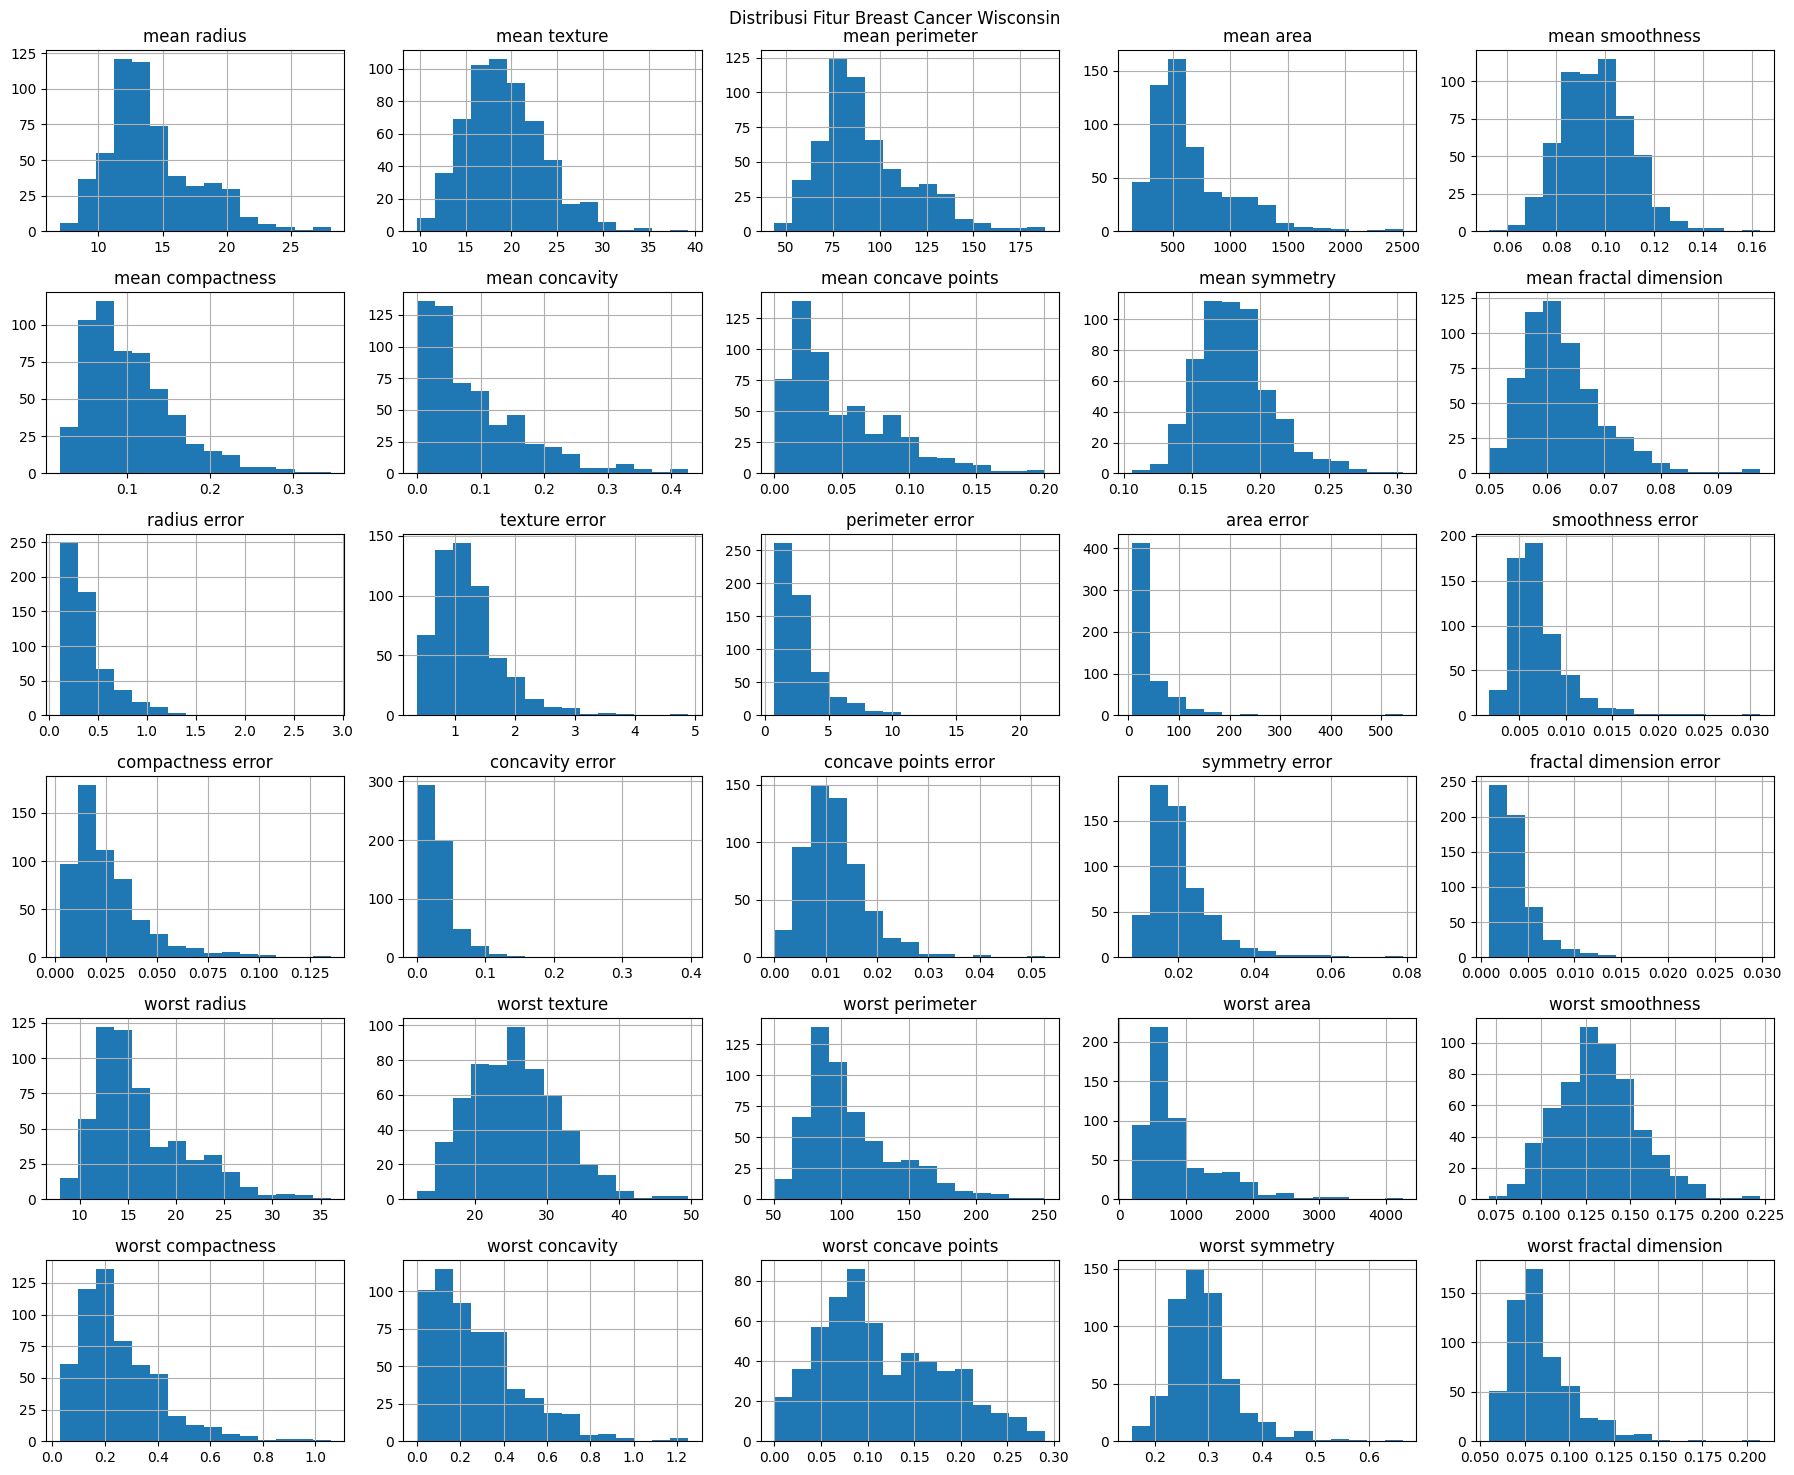

In [4]:
print("Informasi dataset:")
data.info()
print("\nStatistik deskriptif fitur:")
display(data[dataset.feature_names].describe().T)
print("\nJumlah nilai kosong per kolom:")
print(data.isna().sum())
print("\nJumlah baris duplikat:", data.duplicated().sum())
print("\nJumlah data per diagnosis:")
print(data["diagnosis"].value_counts())

data["diagnosis"].value_counts().reindex(dataset.target_names).plot.bar(
    title="Jumlah Data per Diagnosis", xlabel="Diagnosis", ylabel="Jumlah", rot=0
)
plt.tight_layout()
plt.show()

data[dataset.feature_names].hist(figsize=(18, 15), bins=15)
plt.suptitle("Distribusi Fitur Breast Cancer Wisconsin")
plt.tight_layout()
plt.show()

# 5. Data Preprocessing

Pada tahap ini, data dipersiapkan sebelum analisis lebih lanjut. Duplikasi diperiksa tetapi tidak dihapus otomatis. Fitur numerik yang kosong ditangani dengan imputasi median; fitur kemudian distandardisasi. Target sudah berupa angka 0 dan 1 untuk kelas malignant dan benign, sehingga tidak memerlukan encoding tambahan. Data dibagi secara stratified menjadi data latih dan uji. Imputer dan scaler hanya di-fit pada data latih untuk mencegah kebocoran informasi. Notebook ini juga menyimpan data raw serta data train dan test hasil preprocessing menggunakan `to_csv()` pada folder `data/` relatif terhadap working directory notebook.

In [5]:
X = data[dataset.feature_names]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_preprocessed = scaler.fit_transform(X_train_imputed)
X_test_preprocessed = scaler.transform(X_test_imputed)

train_processed = pd.DataFrame(
    X_train_preprocessed, columns=dataset.feature_names
)
train_processed["target"] = y_train.to_numpy()
train_processed["diagnosis"] = train_processed["target"].map(
    dict(enumerate(dataset.target_names))
)

test_processed = pd.DataFrame(
    X_test_preprocessed, columns=dataset.feature_names
)
test_processed["target"] = y_test.to_numpy()
test_processed["diagnosis"] = test_processed["target"].map(
    dict(enumerate(dataset.target_names))
)

raw_dir = Path("data/raw")
processed_dir = Path("data/processed")
raw_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

raw_path = raw_dir / "breast_cancer_raw.csv"
train_path = processed_dir / "breast_cancer_train_preprocessed.csv"
test_path = processed_dir / "breast_cancer_test_preprocessed.csv"
data.to_csv(raw_path, index=False)
train_processed.to_csv(train_path, index=False)
test_processed.to_csv(test_path, index=False)

print("Ukuran data latih:", X_train_preprocessed.shape)
print("Ukuran data uji:", X_test_preprocessed.shape)
print("Jumlah nilai kosong setelah imputasi:", pd.isna(X_train_preprocessed).sum())
print("Label target:", dict(enumerate(dataset.target_names)))
print("Data raw tersimpan di:", raw_path)
print("Data latih tersimpan di:", train_path)
print("Data uji tersimpan di:", test_path)

Ukuran data latih: (455, 30)
Ukuran data uji: (114, 30)
Jumlah nilai kosong setelah imputasi: 0
Label target: {0: 'malignant', 1: 'benign'}
Data raw tersimpan di: data\raw\breast_cancer_raw.csv
Data latih tersimpan di: data\processed\breast_cancer_train_preprocessed.csv
Data uji tersimpan di: data\processed\breast_cancer_test_preprocessed.csv
